# MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications

**Paper:** [arXiv:1704.04861](https://arxiv.org/abs/1704.04861)  
**Authors:** Andrew G. Howard, Menglong Zhu, Bo Chen, Dmitry Kalenichenko, Weijun Wang, Tobias Weyand, Marco Andreetto, Hartwig Adam (Google Inc.)  
**Year:** 2017

## Overview

MobileNets introduce **depthwise separable convolutions** as the building block for efficient CNNs on mobile and embedded devices. A standard convolution is factorized into:
1. **Depthwise convolution** — one spatial filter per input channel (filters)
2. **Pointwise convolution** — a 1×1 conv that combines channels (creates new features)

This reduces computation by **8–9×** for 3×3 kernels with minimal accuracy loss. Two hyper-parameters — **width multiplier** (α) and **resolution multiplier** (ρ) — enable smooth accuracy/latency trade-offs.

In this notebook we:
- Implement depthwise separable convolutions from scratch in PyTorch
- Build a small MobileNet and a standard-convolution equivalent
- Benchmark parameter count, estimated FLOPs, and inference speed
- Train both, at the same width multiplier α = 1.0, on 10,000 CIFAR-10 training images for 4 epochs and compare test accuracy

This is a short run, so both networks only reach about 50% test accuracy; the Summary at the end says what this run found.

## 1. Imports & Setup

In [1]:
import os
# Deterministic cuBLAS kernels; must be set before torch is imported
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import atexit
import contextlib
import io
import shutil
import time
import warnings

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
warnings.filterwarnings('ignore', message='.*deterministic.*')

# One width multiplier for every comparison below (1.0 = the full-width network)
ALPHA = 1.0

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device: cuda
GPU: Tesla T4


## 2. Depthwise Separable Convolution (from scratch)

The core innovation of MobileNets. We split a standard convolution into:
- **Depthwise:** `nn.Conv2d` with `groups=in_channels` — each channel gets its own spatial filter
- **Pointwise:** `nn.Conv2d` with `kernel_size=1` — linear combination of channels

Both are followed by BatchNorm and ReLU, as in the paper (Section 3.1, Figure 3).

In [2]:
class DepthwiseSeparableConv(nn.Module):
    """Depthwise separable convolution: depthwise (spatial) + pointwise (1x1 channel mix).
    
    Standard conv: D_K x D_K x M x N  ->  cost = D_K^2 * M * N * D_F^2
    Depthwise sep:  D_K x D_K x M  +  1 x 1 x M x N  ->  cost = D_K^2 * M * D_F^2 + M * N * D_F^2
    Reduction factor: 1/N + 1/D_K^2  (for 3x3: ~8-9x less compute)
    """
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):
        super().__init__()
        # Depthwise: one filter per channel (groups=in_channels)
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=kernel_size,
                                   stride=stride, padding=padding, groups=in_channels, bias=False)
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.relu1 = nn.ReLU(inplace=True)
        # Pointwise: 1x1 conv to combine channels
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu2 = nn.ReLU(inplace=True)
    
    def forward(self, x):
        x = self.depthwise(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.pointwise(x)
        x = self.bn2(x)
        x = self.relu2(x)
        return x

## 3. Standard Convolution Block (for comparison)

An un-factorized 3×3 convolution with the same input/output channels. This is what MobileNet replaces — the apples-to-apples comparison from Table 4 in the paper.

In [3]:
class StandardConv(nn.Module):
    """Standard 3x3 convolution + BatchNorm + ReLU — the un-factorized baseline."""
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size,
                              stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
    
    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x

## 4. Small MobileNet Architecture

A scaled-down MobileNet for CIFAR-10 (32×32 images, 10 classes). The first layer is a standard 3×3 conv (as in the original paper), followed by depthwise separable blocks. Width multiplier α thins all channel counts.

In [4]:
class SmallMobileNet(nn.Module):
    """Scaled-down MobileNet for CIFAR-10 with width multiplier alpha."""
    def __init__(self, num_classes=10, alpha=1.0):
        super().__init__()
        def ch(c):
            return max(int(c * alpha), 8)  # ensure at least 8 channels
        
        # First layer: standard 3x3 conv (as in paper)
        self.first_conv = nn.Sequential(
            nn.Conv2d(3, ch(32), kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(ch(32)),
            nn.ReLU(inplace=True)
        )
        # Depthwise separable blocks: (in_ch, out_ch, stride)
        self.block1 = DepthwiseSeparableConv(ch(32), ch(64), stride=1)
        self.block2 = DepthwiseSeparableConv(ch(64), ch(128), stride=2)  # downsample
        self.block3 = DepthwiseSeparableConv(ch(128), ch(256), stride=1)
        self.block4 = DepthwiseSeparableConv(ch(256), ch(256), stride=2)  # downsample
        # Global average pooling + FC
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(ch(256), num_classes)
    
    def forward(self, x):
        x = self.first_conv(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

## 5. Standard Convolution Equivalent

Same topology (channel progression, downsampling, pooling, FC head) but every depthwise separable block is replaced by a standard 3×3 convolution. This gives us a fair comparison to measure the factorization benefit.

In [5]:
class SmallStandardNet(nn.Module):
    """Standard-convolution network with same topology as SmallMobileNet."""
    def __init__(self, num_classes=10, alpha=1.0):
        super().__init__()
        def ch(c):
            return max(int(c * alpha), 8)
        
        self.first_conv = nn.Sequential(
            nn.Conv2d(3, ch(32), kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(ch(32)),
            nn.ReLU(inplace=True)
        )
        self.block1 = StandardConv(ch(32), ch(64), stride=1)
        self.block2 = StandardConv(ch(64), ch(128), stride=2)
        self.block3 = StandardConv(ch(128), ch(256), stride=1)
        self.block4 = StandardConv(ch(256), ch(256), stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(ch(256), num_classes)
    
    def forward(self, x):
        x = self.first_conv(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

## 6. Parameter & FLOP Comparison

We count trainable parameters and manually estimate multiply-adds (MACs) for convolution layers. For a standard conv: D_K²·M·N·D_F². For depthwise separable: D_K²·M·D_F² + M·N·D_F².

In [6]:
def count_parameters(model):
    """Count total trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def estimate_macs(model, input_size=(3, 32, 32)):
    """Manually estimate MACs for all Conv2d layers by hooking forward pass."""
    total_macs = 0
    hooks = []
    def hook_fn(module, input, output):
        nonlocal total_macs
        # input: [B, C_in, H, W], output: [B, C_out, H_out, W_out]
        batch_size = input[0].shape[0]
        if isinstance(module, nn.Conv2d):
            kernel_h, kernel_w = module.kernel_size
            out_h, out_w = output.shape[2], output.shape[3]
            # MACs = kernel_h * kernel_w * C_in/groups * C_out * out_h * out_w
            macs = kernel_h * kernel_w * (module.in_channels // module.groups) * module.out_channels * out_h * out_w
            total_macs += macs
    
    # Register hooks on all Conv2d layers
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            hooks.append(m.register_forward_hook(hook_fn))
    
    model.eval()
    with torch.no_grad():
        dummy = torch.randn(1, *input_size).to(next(model.parameters()).device)
        model(dummy)
    
    for h in hooks:
        h.remove()
    
    return total_macs


In [7]:
# Instantiate both models
mobilenet = SmallMobileNet(num_classes=10, alpha=ALPHA).to(device)
standard_net = SmallStandardNet(num_classes=10, alpha=ALPHA).to(device)

# Count parameters
params_mb = count_parameters(mobilenet)
params_std = count_parameters(standard_net)

# Estimate MACs
macs_mb = estimate_macs(mobilenet)
macs_std = estimate_macs(standard_net)

print(f'Width multiplier alpha = {ALPHA}')
print('=' * 65)
print(f'{"Model":<25} {"Parameters":>12} {"MACs":>14} {"MACs Ratio":>12}')
print('=' * 65)
print(f'{"SmallMobileNet":<25} {params_mb:>12,} {macs_mb:>14,} {macs_mb/macs_std:>11.2f}x')
print(f'{"SmallStandardNet":<25} {params_std:>12,} {macs_std:>14,} {"1.00x":>12}')
print('=' * 65)
print(f'\nParameter reduction: {params_std / params_mb:.2f}x fewer parameters in MobileNet')
print(f'MAC reduction:        {macs_std / macs_mb:.2f}x fewer MACs in MobileNet')
print(f'\n(Paper reports 8-9x MAC reduction for 3x3 depthwise separable convolutions)')

# Also show width multiplier effect
print('\n--- Width Multiplier Effect (MobileNet) ---')
for alpha in [1.0, 0.75, 0.5, 0.25]:
    m = SmallMobileNet(num_classes=10, alpha=alpha).to(device)
    p = count_parameters(m)
    macs = estimate_macs(m)
    print(f'  alpha={alpha:.2f}  params={p:>10,}  MACs={macs:>12,}')
    del m

Width multiplier alpha = 1.0
Model                       Parameters           MACs   MACs Ratio
SmallMobileNet                 118,730     18,546,688        0.12x
SmallStandardNet               981,802    151,879,680        1.00x

Parameter reduction: 8.27x fewer parameters in MobileNet
MAC reduction:        8.19x fewer MACs in MobileNet

(Paper reports 8-9x MAC reduction for 3x3 depthwise separable convolutions)

--- Width Multiplier Effect (MobileNet) ---
  alpha=1.00  params=   118,730  MACs=  18,546,688
  alpha=0.75  params=    68,698  MACs=  10,764,288
  alpha=0.50  params=    32,234  MACs=   5,079,040
  alpha=0.25  params=     9,338  MACs=   1,490,944


## 7. Inference Speed Benchmark

We time forward passes of one 32×32 image for both models on the available hardware. Fewer multiply-adds do not guarantee a faster network: the measured times show whether they do here.

In [8]:
def benchmark_inference(model, input_shape=(1, 3, 32, 32), n_warmup=10, n_runs=100):
    """Benchmark inference speed. Returns avg time per forward pass in milliseconds."""
    model.eval()
    dummy = torch.randn(*input_shape).to(next(model.parameters()).device)
    
    # Warm up
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = model(dummy)
    
    # Sync if CUDA
    if device.type == 'cuda':
        torch.cuda.synchronize()
    
    start = time.time()
    with torch.no_grad():
        for _ in range(n_runs):
            _ = model(dummy)
    
    if device.type == 'cuda':
        torch.cuda.synchronize()
    
    elapsed = time.time() - start
    avg_ms = (elapsed / n_runs) * 1000
    return avg_ms


In [9]:
# Benchmark both models
mb_time = benchmark_inference(mobilenet, n_runs=100)
std_time = benchmark_inference(standard_net, n_runs=100)

print(f'MobileNet inference:   {mb_time:.3f} ms per image')
print(f'StandardNet inference: {std_time:.3f} ms per image')
print(f'StandardNet time / MobileNet time: {std_time / mb_time:.2f}x (above 1 means MobileNet is faster)')

MobileNet inference:   1.194 ms per image
StandardNet inference: 0.703 ms per image
StandardNet time / MobileNet time: 0.59x (above 1 means MobileNet is faster)


## 8. Training on CIFAR-10

We train both models, at the same width multiplier, with the same optimizer, learning rate, batch size and number of epochs. To keep the run short, we use only the first 10,000 of the 50,000 CIFAR-10 training images and train for 4 epochs; accuracy is measured on all 10,000 test images.

In [10]:
# Data loading
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

# Download quietly (no progress bars in the saved notebook)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
    testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

from torch.utils.data import Subset
trainset = Subset(trainset, range(10000))  # subset for faster training
train_loader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2,
                          generator=torch.Generator().manual_seed(SEED))
test_loader = DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(f'Training samples: {len(trainset)}')
print(f'Test samples:     {len(testset)}')

Training samples: 10000
Test samples:     10000


In [11]:
def train_model(model, train_loader, test_loader, num_epochs=4, lr=0.001, name='Model'):
    """Train a model and return training history."""
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    criterion = nn.CrossEntropyLoss()
    
    history = {'train_loss': [], 'test_acc': []}
    best_acc = 0.0
    
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        n_batches = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            n_batches += 1
        
        scheduler.step()
        avg_loss = running_loss / n_batches
        
        # Evaluate
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        test_acc = 100 * correct / total
        history['train_loss'].append(avg_loss)
        history['test_acc'].append(test_acc)
        
        if test_acc > best_acc:
            best_acc = test_acc
        
        print(f'[{name}] Epoch {epoch+1}/{num_epochs}  loss={avg_loss:.4f}  test_acc={test_acc:.2f}%')
    
    print(f'\n[{name}] Best test accuracy: {best_acc:.2f}%')
    return history, best_acc


### 8.1 Train SmallMobileNet

In [12]:
print(f'Training SmallMobileNet (alpha={ALPHA})...\n')
torch.manual_seed(SEED)
mobilenet = SmallMobileNet(num_classes=10, alpha=ALPHA).to(device)
mb_history, mb_best = train_model(mobilenet, train_loader, test_loader, 
                                   num_epochs=4, lr=0.001, name='MobileNet')

Training SmallMobileNet (alpha=1.0)...



[MobileNet] Epoch 1/4  loss=1.8777  test_acc=38.15%


[MobileNet] Epoch 2/4  loss=1.5893  test_acc=43.84%


[MobileNet] Epoch 3/4  loss=1.4631  test_acc=47.96%


[MobileNet] Epoch 4/4  loss=1.3902  test_acc=49.38%

[MobileNet] Best test accuracy: 49.38%


### 8.2 Train SmallStandardNet

In [13]:
print(f'Training SmallStandardNet (alpha={ALPHA})...\n')
torch.manual_seed(SEED)
standard_net = SmallStandardNet(num_classes=10, alpha=ALPHA).to(device)
std_history, std_best = train_model(standard_net, train_loader, test_loader, 
                                      num_epochs=4, lr=0.001, name='StandardNet')

Training SmallStandardNet (alpha=1.0)...



[StandardNet] Epoch 1/4  loss=1.7619  test_acc=33.65%


[StandardNet] Epoch 2/4  loss=1.4679  test_acc=41.54%


[StandardNet] Epoch 3/4  loss=1.3059  test_acc=51.57%


[StandardNet] Epoch 4/4  loss=1.1885  test_acc=55.36%

[StandardNet] Best test accuracy: 55.36%


## 9. Results Comparison

Parameter count, measured inference time (from Section 7) and test accuracy per epoch, all for the two models trained above (α = 1.0).

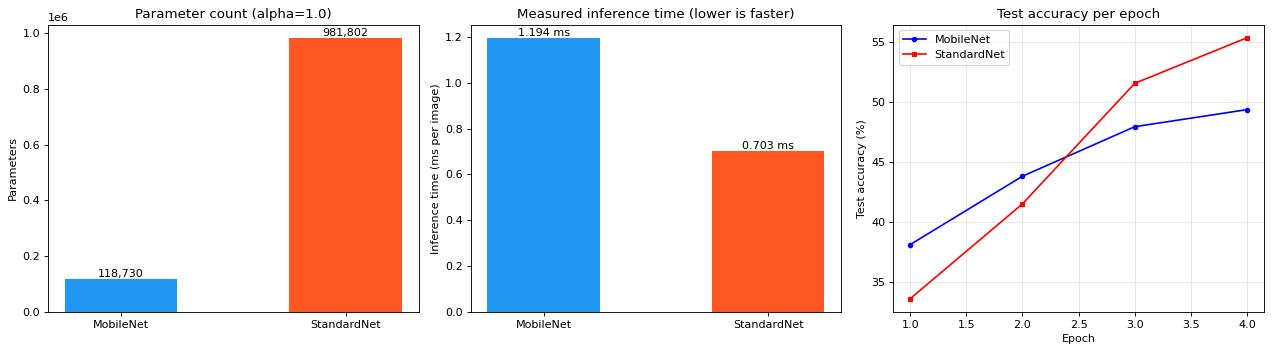

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
models = ['MobileNet', 'StandardNet']
colors = ['#2196F3', '#FF5722']

# 1. Parameter count
ax = axes[0]
params = [count_parameters(mobilenet), count_parameters(standard_net)]
bars = ax.bar(models, params, color=colors, width=0.5)
ax.set_ylabel('Parameters')
ax.set_title(f'Parameter count (alpha={ALPHA})')
for bar, p in zip(bars, params):
    ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height(), f'{p:,}', ha='center', va='bottom', fontsize=10)

# 2. Inference time measured in Section 7 (lower is faster)
ax = axes[1]
times = [mb_time, std_time]
bars = ax.bar(models, times, color=colors, width=0.5)
ax.set_ylabel('Inference time (ms per image)')
ax.set_title('Measured inference time (lower is faster)')
for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height(), f'{t:.3f} ms', ha='center', va='bottom', fontsize=10)

# 3. Test accuracy per epoch
ax = axes[2]
ax.plot(range(1, len(mb_history['test_acc']) + 1), mb_history['test_acc'], 'b-o', label='MobileNet', markersize=4)
ax.plot(range(1, len(std_history['test_acc']) + 1), std_history['test_acc'], 'r-s', label='StandardNet', markersize=4)
ax.set_xlabel('Epoch')
ax.set_ylabel('Test accuracy (%)')
ax.set_title('Test accuracy per epoch')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Final Numbers

In [15]:
p_mb, p_std = count_parameters(mobilenet), count_parameters(standard_net)
m_mb, m_std = estimate_macs(mobilenet), estimate_macs(standard_net)
print('=' * 72)
print(f'          MobileNet vs StandardNet, both at alpha = {ALPHA}')
print('=' * 72)
print(f'{"Metric":<30} {"MobileNet":>13} {"StandardNet":>13} {"Std / Mob":>11}')
print('-' * 72)
print(f'{"Parameters":<30} {p_mb:>13,} {p_std:>13,} {p_std / p_mb:>10.2f}x')
print(f'{"Estimated MACs":<30} {m_mb:>13,} {m_std:>13,} {m_std / m_mb:>10.2f}x')
print(f'{"Best test accuracy (%)":<30} {mb_best:>13.2f} {std_best:>13.2f}')
print(f'{"Inference (ms per image)":<30} {mb_time:>13.3f} {std_time:>13.3f} {std_time / mb_time:>10.2f}x')
print('=' * 72)
print(f'Accuracy difference (StandardNet - MobileNet): {std_best - mb_best:+.2f} points')

          MobileNet vs StandardNet, both at alpha = 1.0
Metric                             MobileNet   StandardNet   Std / Mob
------------------------------------------------------------------------
Parameters                           118,730       981,802       8.27x
Estimated MACs                    18,546,688   151,879,680       8.19x
Best test accuracy (%)                 49.38         55.36
Inference (ms per image)               1.194         0.703       0.59x
Accuracy difference (StandardNet - MobileNet): +5.98 points


## 11. Summary

### What the run above shows

- **Size and computation:** with the same layout and the same width (α = 1.0), the MobileNet has 118,730 parameters and needs 18.5 million multiply-adds for one 32×32 image, against 981,802 parameters and 151.9 million multiply-adds for the standard network: 8.27× fewer parameters and 8.19× fewer multiply-adds, in line with the paper's 8 to 9 times (Section 3.1).
- **Speed:** on the T4 GPU, one forward pass of a single image was **slower** for the MobileNet: about 1 ms against about 0.65 ms for the standard network. The exact times, printed above, vary between runs: in three runs the MobileNet took 0.93, 1.14 and 1.21 ms and the standard network 0.62, 0.66 and 0.68 ms, so the standard network was 1.5–1.8× faster. Fewer multiply-adds did not make this small network faster here: at batch size 1 on tiny images the GPU is mostly waiting on many small operations, and depthwise convolutions run less efficiently than dense ones. The paper's speed argument is about where the computation goes on its hardware, not a guarantee for every device.
- **Accuracy:** trained the same way on only 10,000 CIFAR-10 images for 4 epochs, the MobileNet reached 49.38% test accuracy and the standard network 55.36%, a gap of about 6 points. Both are far from trained: about 50% is what this short run gives, not what these networks can reach. The paper's ImageNet gap between depthwise separable and full convolutions was 1.1 points (70.6% vs 71.7%, Table 4), with full training.

An earlier version of this notebook compared parameter counts at α = 0.5 with accuracies at α = 1.0 for MobileNet and α = 0.5 for the standard network, and called the result a "dramatic efficiency gain" with "minimal accuracy loss" although the MobileNet was slower in its own measurements.

## References

- Howard, A. G. et al. (2017). *MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications*. arXiv:1704.04861.
- Sifre, L. (2014). *Rigid-Motion Scattering for Image Classification*. PhD thesis. (Depthwise separable convolutions, as cited by the MobileNets paper.)
- Chollet, F. (2016). *Xception: Deep Learning with Depthwise Separable Convolutions*. arXiv:1610.02357.
- Sandler, M. et al. (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks*. arXiv:1801.04381.